### 이진 분류 실습 문제 1

## Iris Dataset
: 붓꽃의 꽃받침과 꽃잎의 측정값을 이용해 Setosa와 Versicolor 두 품종을 구분하는 이진 분류 모델 구현.

- 전체 데이터: 150개
- 이번 실습에서 사용할 데이터: 100개
- 입력 특징: 4개
- 정답: 꽃 품종 (Setosa 또는 Versicolor)

| 열 이름 | 의미 | 설명 |
|:---:|:---:|:---|
| `sepal_length` | 꽃받침 길이 | 꽃받침의 길이, cm |
| `sepal_width` | 꽃받침 너비 | 꽃받침의 너비, cm |
| `petal_length` | 꽃잎 길이 | 꽃잎의 길이, cm |
| `petal_width` | 꽃잎 너비 | 꽃잎의 너비, cm |
| `species` | 꽃 품종 | `setosa`, `versicolor`, `virginica` |


#### Step1. 데이터 불러오기 및 전처리

**실습 조건**
- `setosa`와 `versicolor` 두 품종만 사용하고 `virginica`는 제외한다.
- `setosa`는 클래스 0, `versicolor`는 클래스 1로 변환한다.
- 4개의 측정값을 입력값(X), 품종 레이블을 정답(y)으로 사용한다.
- 학습 데이터와 테스트 데이터를 8:2 비율로 분리한다.
- 학습 데이터의 평균과 표준편차를 이용해 입력 특징을 표준화한다.

In [25]:
import pandas as pd
import torch
from torch import nn, optim
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
import numpy as np

torch.manual_seed(42)

In [26]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
df = pd.read_csv(url)

print(df.head())
print("데이터 크기:", df.shape)
print("\n품종별 데이터 개수:")
print(df["species"].value_counts())


# Setosa와 Versicolor만 선택
df = df[df["species"].isin(["setosa", "versicolor"])].copy()

# 입력 데이터(X)와 정답 데이터(y) 분리
X = torch.tensor(df[["sepal_length", "sepal_width", "petal_length", "petal_width"]].values,
                 dtype=torch.float32)

y_values = df["species"].map({"setosa": 0, "versicolor": 1}).values
y = torch.tensor(y_values, dtype=torch.float32).reshape(-1, 1)

# 클래스별로 학습/테스트 데이터를 나누어 클래스 비율 유지
torch.manual_seed(42)

train_indices = []
test_indices = []

for class_value in [0, 1]:

    class_indices = torch.where(y.squeeze() == class_value)[0]
    class_indices = class_indices[torch.randperm(len(class_indices))]

    split = int(len(class_indices) * 0.8)

    train_indices.extend(class_indices[:split].tolist())    # list
    test_indices.extend(class_indices[split:].tolist())

# 학습/테스트 인덱스 섞기
train_indices = torch.tensor(train_indices)[torch.randperm(len(train_indices))]
test_indices = torch.tensor(test_indices)[torch.randperm(len(test_indices))]

# 학습/테스트 데이터 분리
X_train = X[train_indices]
X_test = X[test_indices]
y_train = y[train_indices]
y_test = y[test_indices]

# 학습 데이터의 평균과 표준편차로 표준화
mean = X_train.mean(dim=0)
std = X_train.std(dim=0).clamp(min=1e-8)

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

print("\nX_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa
데이터 크기: (150, 5)

품종별 데이터 개수:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

X_train: torch.Size([80, 4])
y_train: torch.Size([80, 1])
X_test: torch.Size([20, 4])
y_test: torch.Size([20, 1])


#### Step2. 모델 만들기

**목표:** Banknote Authentication 실습에서 사용한 MLP 구조로 붓꽃 품종을 분류한다.

- 입력 노드: 4개
- 은닉층: 100개 노드
- 출력 노드: 1개
- 출력 활성화 함수: Sigmoid
- 예측값이 0.5 이상이면 클래스 1, 0.5 미만이면 클래스 0

In [27]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Sequential(
            nn.Linear(4, 100),
            nn.Sigmoid(),
            nn.Linear(100, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.linear(x)

model = MLP()

#### STEP 3. 모델 학습시키기

- Optimizer: SGD
- Loss function: BCELoss
- 학습률(LR): 0.1
- Epoch: 100
- Batch size: 16 또는 32

Epoch:  10, Train Loss: 0.1673
Epoch:  20, Train Loss: 0.0738
Epoch:  30, Train Loss: 0.0447
Epoch:  40, Train Loss: 0.0314
Epoch:  50, Train Loss: 0.0237
Epoch:  60, Train Loss: 0.0189
Epoch:  70, Train Loss: 0.0157
Epoch:  80, Train Loss: 0.0133
Epoch:  90, Train Loss: 0.0116
Epoch: 100, Train Loss: 0.0102


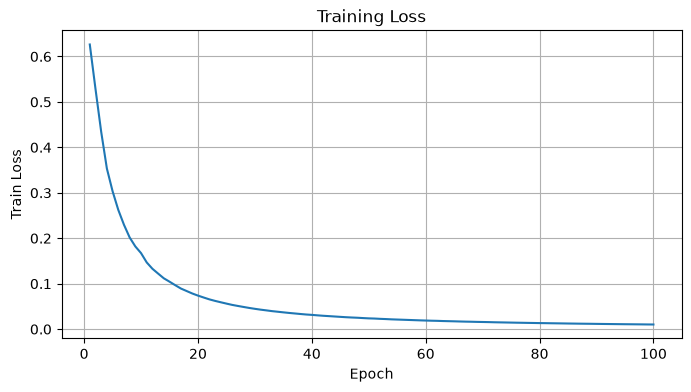

In [28]:
BATCH_SIZE = 16
LR = 1e-1
EPOCH = 100

train_DS = TensorDataset(X_train, y_train)
train_DL = DataLoader(train_DS, batch_size=BATCH_SIZE, shuffle=True)

N = len(train_DL.dataset)

optimizer = optim.SGD(model.parameters(), lr=LR)
criterion = nn.BCELoss()

loss_history = []

model.train()
for ep in range(EPOCH):
    rloss = 0.0

    for x_batch, y_batch in train_DL:
        y_hat = model(x_batch)
        loss = criterion(y_hat, y_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        rloss += loss.item() * x_batch.shape[0]

    epoch_loss = rloss / N
    loss_history.append(epoch_loss)

    if (ep + 1) % 10 == 0:
        print(f"Epoch: {ep+1:3d}, Train Loss: {epoch_loss:.4f}")

plt.figure(figsize=(8, 4))
plt.plot(range(1, EPOCH + 1), loss_history)
plt.xlabel("Epoch")
plt.ylabel("Train Loss")
plt.title("Training Loss")
plt.grid(True)
plt.show()

#### Step4. 모델 테스트하기

- Sigmoid 출력값에 임계값 0.5를 적용해 클래스를 예측.
- 전체 테스트 데이터 중 정답을 맞힌 개수와 Accuracy(%)를 출력.

In [29]:
model.eval()

with torch.no_grad():
    y_prob = model(X_test)
    y_pred = (y_prob >= 0.5).float()

correct = (y_pred == y_test).sum().item()
total = y_test.shape[0]
accuracy = correct / total * 100

print(f"정답 개수: {correct} / {total}")
print(f"Accuracy: {accuracy:.2f}%")

정답 개수: 20 / 20
Accuracy: 100.00%


#### Step5. 테스트 결과 시각화

- 실제 클래스와 예측 클래스를 이용해 2×2 혼동행렬(Confusion Matrix)을 작성.
- 실제 클래스별 예측 확률 분포를 히스토그램으로 나타내시오.
- 혼동행렬의 행은 실제 클래스, 열은 예측 클래스로 표시하시오.
- 클래스 0과 클래스 1이 무엇을 의미하는지 그래프에 표시하시오.

Confusion Matrix
tensor([[10,  0],
        [ 0, 10]])


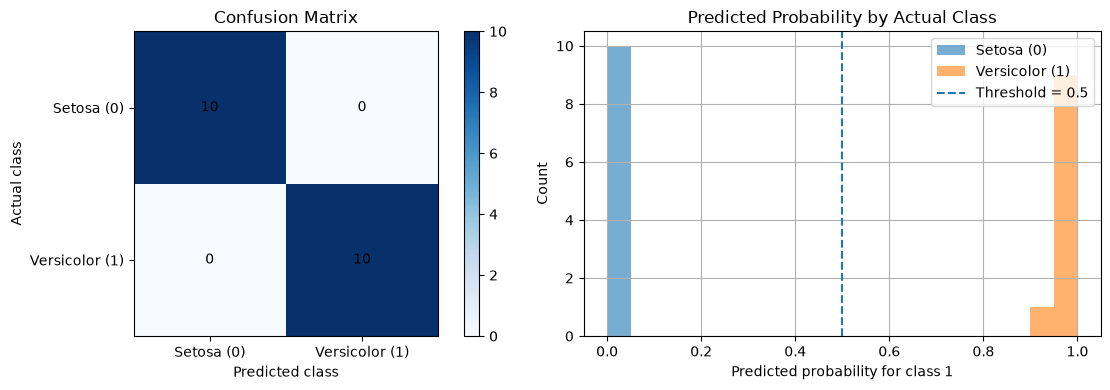

In [35]:
# 혼동행렬: 행=실제 클래스, 열=예측 클래스
confusion = torch.zeros((2, 2), dtype=torch.int64)

for actual, predicted in zip(y_test.squeeze().int(), y_pred.squeeze().int()):
    confusion[actual, predicted] += 1

print("Confusion Matrix")
print(confusion)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 혼동행렬 시각화
im = axes[0].imshow(confusion.numpy(), cmap="Blues")
axes[0].set_title("Confusion Matrix")
axes[0].set_xlabel("Predicted class")
axes[0].set_ylabel("Actual class")
axes[0].set_xticks([0, 1], ["Setosa (0)", "Versicolor (1)"])
axes[0].set_yticks([0, 1], ["Setosa (0)", "Versicolor (1)"])

for i in range(2):
    for j in range(2):
        axes[0].text(j, i, int(confusion[i, j]), ha="center", va="center")

fig.colorbar(im, ax=axes[0])

# 실제 클래스별 예측 확률 분포
prob_np = y_prob.squeeze().numpy()
actual_np = y_test.squeeze().numpy()

bins = np.linspace(0,1,21)
axes[1].hist(prob_np[actual_np == 0], bins=bins, alpha=0.6, label="Setosa (0)")
axes[1].hist(prob_np[actual_np == 1], bins=bins, alpha=0.6, label="Versicolor (1)")
axes[1].axvline(0.5, linestyle='--', label='Threshold = 0.5')
axes[1].set_xlabel("Predicted probability for class 1")
axes[1].set_ylabel("Count")
axes[1].set_title("Predicted Probability by Actual Class")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

#### STEP 6. 파라미터 개수 확인

In [31]:
# 층별 파라미터 수
layer1_params = sum(p.numel() for p in model.linear[0].parameters())
layer2_params = sum(p.numel() for p in model.linear[2].parameters())
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"입력층-은닉층 파라미터: {layer1_params:,}")
print(f"은닉층-출력층 파라미터: {layer2_params:,}")
print(f"전체 학습 가능 파라미터: {total_params:,}")

입력층-은닉층 파라미터: 500
은닉층-출력층 파라미터: 101
전체 학습 가능 파라미터: 601
